# Plaquette eigenbasis vs. spin basis for the ViT wave function

**2D J1–J2 Heisenberg model, square lattice.** One Vision Transformer, two local bases:

* **Spin basis**: each token is a 2×2 patch of σᶻ spins (`spinbasis/`, the NetKet ViT tutorial architecture).
* **Plaquette eigenbasis**: each token is the index (0–15) of the 2×2-plaquette *eigenstate* the patch occupies (`eigenbasis/`).

On 6×6 at J2 = 0 the two networks are matched: the same 9 tokens, the same factored translation-invariant attention, the same log-cosh head, ~117k parameters each. **The spin basis reaches a relative energy error of 5×10⁻⁶; the best eigenbasis run, even with 433k parameters and 26k steps, stalls at 7.6×10⁻⁴.**

## Summary: why the eigenbasis is worse in this approach

**In one line:** rotating each plaquette into its eigenbasis turns a sign-free problem into one with a complicated sign structure. The ViT cannot learn that sign structure, and neither the network architecture nor the sampler fixes it.

1. **The gap is large and immediate (§2).** At matched size (117k parameters) the spin basis is at 5×10⁻⁶ after 10k steps vs 3.3×10⁻³ for the eigenbasis. The gap is already there at step 100, so this is not slow late-stage optimisation.
2. **The eigenbasis sign structure cannot be gauged away (§4).** Neither network was given a stoquastic Hamiltonian. All runs used no Marshall rotation, so the spin-basis Hamiltonian *as run* has 100% positive off-diagonal weight. But one simple gauge (Marshall's) brings it to 0% at J2 = 0, and the spin ViT learns that sign by itself. In the eigenbasis the best of all 2¹⁶ per-state sign gauges still leaves **46%** positive (random signs would give 50%).
3. **So the ground state has a hard sign structure (§5).** Exact 4×4 ground state, the share of weight whose sign the best simple rule gets wrong: **0.000 (spin) vs 0.066 (eigen)** at J2 = 0, and **0.013 vs 0.158** at J2 = 0.5. The eigenbasis is worse in the frustrated regime too, not only at J2 = 0.
4. **The sign is what the network cannot learn (§6).** Fitting the ViT *directly* to the exact 4×4 ground state (no sampling, no VMC): spin infidelity ≈ 4×10⁻³, eigenbasis 0.13–0.25. Give the eigenbasis network the exact signs and it reaches **2.2×10⁻³ / 2.6×10⁻³**, as good as spin, in 3 of 4 runs. Five architecture variants (content-dependent attention, a separate phase head) never get within 2× of spin.
5. **Sampling is not the cause (§3).** |ψ|² is very concentrated in the eigenbasis: on 4×4, 99% of the weight sits on 744 vs 9,678 configurations. At α = 2 the Metropolis acceptance collapses to 0.07 and the result gets *worse*, so overdispersed sampling (α = 1.25) is needed. But sampling choices move the eigenbasis by < 2×, against a ~900× gap.

**Caveats:**
* The sign-structure and fit experiments are 4×4 (4 plaquettes).
* The gauge search applies the same sign rule on every plaquette.
* Fits use 2 seeds.
* All 6×6 comparisons are at J2 = 0, where the spin basis is sign-free, the most favourable case for it. The spin ViT has not yet been run at 6×6 J2 ≈ 0.5 (exact references exist; §7).
* On 4×4 the spin basis's sign advantage narrows deep in the frustrated regime: 10.2% vs 16.9% wrong-sign weight at J2 = 0.6 (§5).

## 1. Setup and data

Every number below is computed in this notebook from the run files. Nothing is pasted in. Paths are resolved relative to this notebook: the repo's `data/` holds `spinbasis/`, `eigenbasis/` and `diagnostics/`, so it re-runs unchanged on the cluster.

In [1]:
%matplotlib inline
import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import Markdown, display

def _find(name):
    here = Path.cwd().resolve()
    for base in (here, *here.parents):
        if (base / name).is_dir():
            return base / name
    raise FileNotFoundError(f"no {name!r} at or above {here}")

REPO = _find("data").parent              # heisenberg_2d/
DATA = REPO / "data" / "eigenbasis"; MASTER = REPO.parent
SPIN_DATA = REPO / "data" / "spinbasis"
DIAG_DIR = sorted((REPO / "data" / "diagnostics" / "sign_4x4").iterdir())[-1]
REFS = json.load(open(MASTER / "importance_sampling_nqs" / "energy_ref_litt.json"))
E0_SITE = -0.678872      # 6x6, J2=0, per site: the reference every run in this project uses
print("data:        ", DATA)
print("spin data:   ", SPIN_DATA)
print("4x4 fits:    ", DIAG_DIR.name)
print("6x6 J2=0 literature: QMC", REFS["Square_Heisenberg"]["1"]["6"]["qmc"],
      "| this project uses", E0_SITE, "-> relErr below ~1.5e-6 is below the reference's precision")

# ---- one colour per entity, used in every figure ---------------------------
C_SPIN, C_EIG, C_ORACLE, C_MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "lines.markersize": 7, "legend.frameon": False,
    "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})

def table(headers, rows):
    """Markdown table (the table view behind every figure)."""
    out = "| " + " | ".join(headers) + " |\n|" + "|".join("---" for _ in headers) + "|\n"
    out += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(out))

data:         /Users/ashilcusky/Documents/master/heisenberg_2d/data/eigenbasis
spin data:    /Users/ashilcusky/Documents/master/heisenberg_2d/data/spinbasis
4x4 fits:     2026-10-06_11-36-51G261eafe
6x6 J2=0 literature: QMC -0.678873 | this project uses -0.678872 -> relErr below ~1.5e-6 is below the reference's precision


In [2]:
def _real(x):
    if isinstance(x, dict):
        x = x["real"]
    return [np.nan if v is None else v for v in x]

def _n_params(rd):
    """From the run's summary/stdout, else (for branched runs) from the parent run."""
    s = rd / "run.summary.json"
    if s.exists() and "n_params" in json.load(open(s)):
        return json.load(open(s))["n_params"]
    for p in [rd / "stdout.txt"]:
        if p.exists():
            m = re.findall(r"n_params\s*=?\s*(\d+)", p.read_text(errors="replace"))
            if m:
                return int(m[-1])
    par = rd / "parent.json"
    if par.exists():
        pj = json.load(open(par))["parent"]
        return _n_params(DATA / pj["sweep_id"] / f"run_{int(pj['run_id']):04d}")
    return None

def load_run(rd):
    """Merge every *.log in a run dir (resubmissions), keep the last occurrence per iteration."""
    rd = Path(rd)
    its, E, V, T = [], [], [], []
    for lp in sorted(rd.glob("*.log")):
        try:
            d = json.load(open(lp))["Energy"]
        except Exception:
            continue
        n = len(d["iters"])
        its += d["iters"]; E += _real(d["Mean"])
        V += _real(d.get("Variance", [None] * n)); T += _real(d.get("TauCorr", [None] * n))
    it, E, V, T = (np.asarray(a, float) for a in (its, E, V, T))
    o = np.argsort(it, kind="stable"); it, E, V, T = it[o], E[o], V[o], T[o]
    _, first_rev = np.unique(it[::-1], return_index=True)
    keep = np.sort(len(it) - 1 - first_rev)
    diag = []
    if (rd / "run.diag.jsonl").exists():
        diag = [json.loads(l) for l in open(rd / "run.diag.jsonl") if l.strip()]
    cfg = json.load(open(rd / "config.json"))
    return dict(it=it[keep], E=E[keep], var=V[keep], tau=T[keep], diag=diag, cfg=cfg,
                n_params=_n_params(rd), N=cfg["system"]["L"] ** 2)

def run_dir(root, sweep_prefix, run):
    hits = sorted(Path(root).glob(sweep_prefix + "*"))
    assert hits, f"no sweep {sweep_prefix} under {root}"
    return hits[0] / f"run_{run:04d}"

# label, basis, directory, emphasis
RUNS = {
    "spin_vit":   ("Spin ViT, L2, d=72",                 "spin",  run_dir(SPIN_DATA, "2026-09-28_15-04-11", 3), True),
    "spin_vit36": ("Spin ViT, L2, d=36",                 "spin",  run_dir(SPIN_DATA, "2026-09-30_15-42-22", 2), False),
    "spin_vitp3": ("Spin ViT, L2, d=72, 3x3 patches",    "spin",  run_dir(SPIN_DATA, "2026-09-30_15-42-22", 3), False),
    "spin_rbm":   ("Spin RBM, alpha=2 (context)",        "other", run_dir(SPIN_DATA, "2026-09-28_15-04-11", 2), False),
    "eig_best":   ("Eigen ViT, L8 (best run, 26k steps)", "eigen", run_dir(DATA, "2026-10-05_14-21-35", 0), True),
    "eig_L2":     ("Eigen ViT, L2 (matched size)",        "eigen", run_dir(DATA, "2026-09-21_12-33-47", 0), False),
    "eig_L2k":    ("Eigen ViT, L2 + Klein projection",    "eigen", run_dir(DATA, "2026-09-21_12-38-57", 0), False),
    "eig_L2a2":   ("Eigen ViT, L2, alpha=2",              "eigen", run_dir(DATA, "2026-10-06_11-43-04", 0), False),
}
R = {k: load_run(v[2]) for k, v in RUNS.items()}
for k, r in R.items():
    print(f"{k:11s} {RUNS[k][0]:40s} params={r['n_params']}  iters={int(r['it'][-1]) + 1}")

spin_vit    Spin ViT, L2, d=72                       params=116784  iters=10000
spin_vit36  Spin ViT, L2, d=36                       params=29880  iters=10000
spin_vitp3  Spin ViT, L2, d=72, 3x3 patches          params=117024  iters=10000
spin_rbm    Spin RBM, alpha=2 (context)              params=2700  iters=10000
eig_best    Eigen ViT, L8 (best run, 26k steps)      params=433296  iters=26000
eig_L2      Eigen ViT, L2 (matched size)             params=116856  iters=10000
eig_L2k     Eigen ViT, L2 + Klein projection         params=116856  iters=10000
eig_L2a2    Eigen ViT, L2, alpha=2                   params=116856  iters=2000


## 2. Headline: 6×6, J2 = 0, relative energy error vs. optimisation step

Energies are averaged in log-spaced bins of steps before taking |E − E0|/|E0|. Spin-basis runs are blue and eigenbasis runs orange; the strongest run of each basis is drawn heavier.

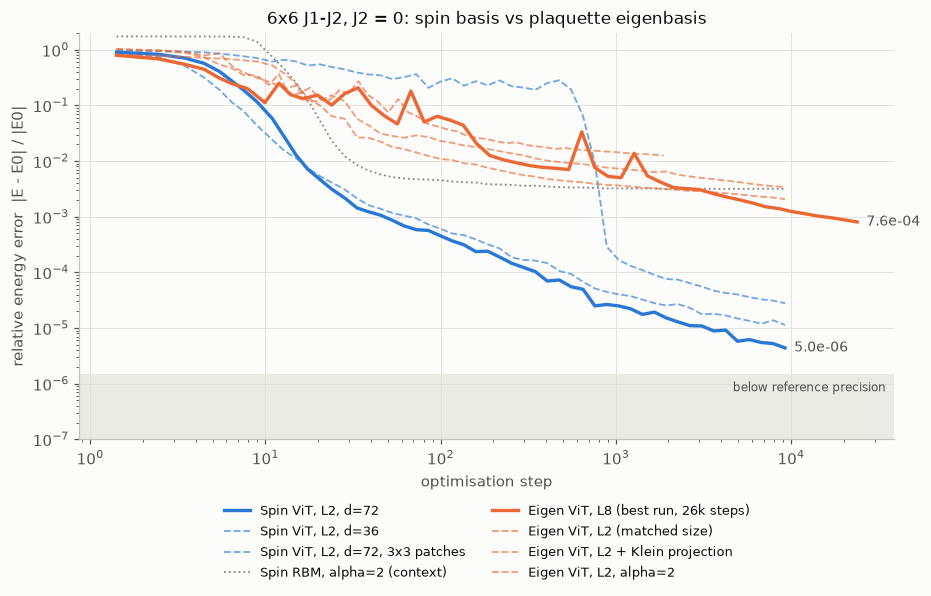

In [3]:
def binned_relerr(r, nbins=60):
    it, E = r["it"], r["E"] / r["N"]
    edges = np.unique(np.geomspace(1, it.max() + 1, nbins).astype(int))
    x, y = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        sel = (it >= a) & (it < b) & np.isfinite(E)
        if sel.any():
            x.append(np.sqrt(a * b)); y.append(abs(E[sel].mean() - E0_SITE) / abs(E0_SITE))
    return np.array(x), np.array(y)

style = {"spin": C_SPIN, "eigen": C_EIG, "other": C_MUTED}
fig, ax = plt.subplots(figsize=(8.6, 5.6))
for k, (label, basis, _, main) in RUNS.items():
    x, y = binned_relerr(R[k])
    ls = ":" if basis == "other" else ("-" if main else "--")
    ax.loglog(x, y, color=style[basis], lw=2.2 if main else 1.2, ls=ls,
              alpha=1.0 if main or basis == "other" else 0.65, label=label)
    if main:   # label = the same final value as the table below (mean of the last 500 steps)
        r = R[k]; n = len(r["E"])
        fin = abs(np.nanmean(r["E"][max(0, n - 500):]) / r["N"] - E0_SITE) / abs(E0_SITE)
        ax.annotate(f"{fin:.1e}", (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", color=INK2, fontsize=9)
ax.axhspan(1e-7, 1.5e-6, color=GRID, alpha=0.6, lw=0)
ax.text(0.99, 1.1e-6, "below reference precision", color=INK2, fontsize=8, va="top", ha="right",
        transform=ax.get_yaxis_transform())
ax.set_xlabel("optimisation step"); ax.set_ylabel("relative energy error  |E - E0| / |E0|")
ax.set_ylim(1e-7, 2); ax.set_title("6x6 J1-J2, J2 = 0: spin basis vs plaquette eigenbasis")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=8.5, ncol=2)
fig.tight_layout(); plt.show()

In [4]:
rows = []
for k, (label, basis, _, main) in RUNS.items():
    r = R[k]; d = r["cfg"]["distribution"]
    n = len(r["E"]); tail = slice(max(0, n - 500), n)
    e = np.nanmean(r["E"][tail]) / r["N"]
    var = np.nanmean(r["var"][tail]); E_tot = np.nanmean(r["E"][tail])
    at = lambda s: (abs(np.nanmean(r["E"][(r["it"] >= s - 50) & (r["it"] < s + 50)]) / r["N"] - E0_SITE) / abs(E0_SITE)
                    if ((r["it"] >= s - 50) & (r["it"] < s + 50)).any() else float("nan"))
    rows.append([label, basis, f"{r['n_params']:,}" if r["n_params"] else "?",
                 r["cfg"]["sampler"].get("N_SAMPLES", int(2048 * r["cfg"]["sampler"].get("MONTECARLO", 0))),
                 f"{d['alpha']}{' (auto)' if d.get('auto_alpha') else ''}",
                 f"{at(100):.1e}", f"{at(1000):.1e}", f"{at(10000):.1e}",
                 int(r["it"][-1]) + 1, f"**{abs(e - E0_SITE) / abs(E0_SITE):.1e}**",
                 f"{r['N'] * var / E_tot ** 2:.1e}"])
table(["run", "basis", "params", "samples", "alpha (IS)", "relErr @100", "@1k", "@10k",
       "steps", "final relErr", "V-score"], rows)
display(Markdown("*final relErr = mean energy over the last 500 steps. V-score = N·Var(E)/E² "
                 "(→ 0 for an eigenstate); for alpha ≠ 2 the logged variance is an importance-"
                 "weighted estimate, so compare V-scores within the same alpha.*"))

| run | basis | params | samples | alpha (IS) | relErr @100 | @1k | @10k | steps | final relErr | V-score |
|---|---|---|---|---|---|---|---|---|---|---|
| Spin ViT, L2, d=72 | spin | 116,784 | 8192 | 2.0 | 4.8e-04 | 2.7e-05 | 5.3e-06 | 10000 | **5.0e-06** | 6.3e-05 |
| Spin ViT, L2, d=36 | spin | 29,880 | 8192 | 2.0 | 6.9e-04 | 4.1e-05 | 1.5e-05 | 10000 | **1.2e-05** | 1.5e-04 |
| Spin ViT, L2, d=72, 3x3 patches | spin | 117,024 | 8192 | 2.0 | 2.7e-01 | 1.9e-04 | 3.4e-05 | 10000 | **2.8e-05** | 3.6e-04 |
| Spin RBM, alpha=2 (context) | other | 2,700 | 8192 | 2.0 | 4.5e-03 | 3.2e-03 | 3.2e-03 | 10000 | **3.2e-03** | 2.7e-02 |
| Eigen ViT, L8 (best run, 26k steps) | eigen | 433,296 | 8192 | 1.25 (auto) | 6.6e-02 | 5.3e-03 | 1.3e-03 | 26000 | **7.6e-04** | 3.6e-03 |
| Eigen ViT, L2 (matched size) | eigen | 116,856 | 8192 | 1.25 | 2.4e-02 | 7.4e-03 | 3.3e-03 | 10000 | **3.4e-03** | 9.7e-03 |
| Eigen ViT, L2 + Klein projection | eigen | 116,856 | 8192 | 1.25 | 1.2e-02 | 3.7e-03 | 2.0e-03 | 10000 | **2.0e-03** | 4.0e-03 |
| Eigen ViT, L2, alpha=2 | eigen | 116,856 | 8192 | 2.0 | 5.0e-02 | 1.4e-02 | nan | 2000 | **1.3e-02** | 9.6e-02 |

*final relErr = mean energy over the last 500 steps. V-score = N·Var(E)/E² (→ 0 for an eigenstate); for alpha ≠ 2 the logged variance is an importance-weighted estimate, so compare V-scores within the same alpha.*

## 3. Sampling statistics: real, but not the cause

The eigenbasis |ψ|² is concentrated on few configurations (§5: 744 vs 9,678 hold 99% of the 4×4 weight), so the Hamiltonian-move Metropolis sampler struggles at α = 2. With overdispersion (q ∝ |ψ|^1.25) acceptance recovers to ~0.28, at the price of a ~9% importance-weight ESS. Either way, the eigenbasis energy moves by < 2× while the gap to the spin basis is ~10³.

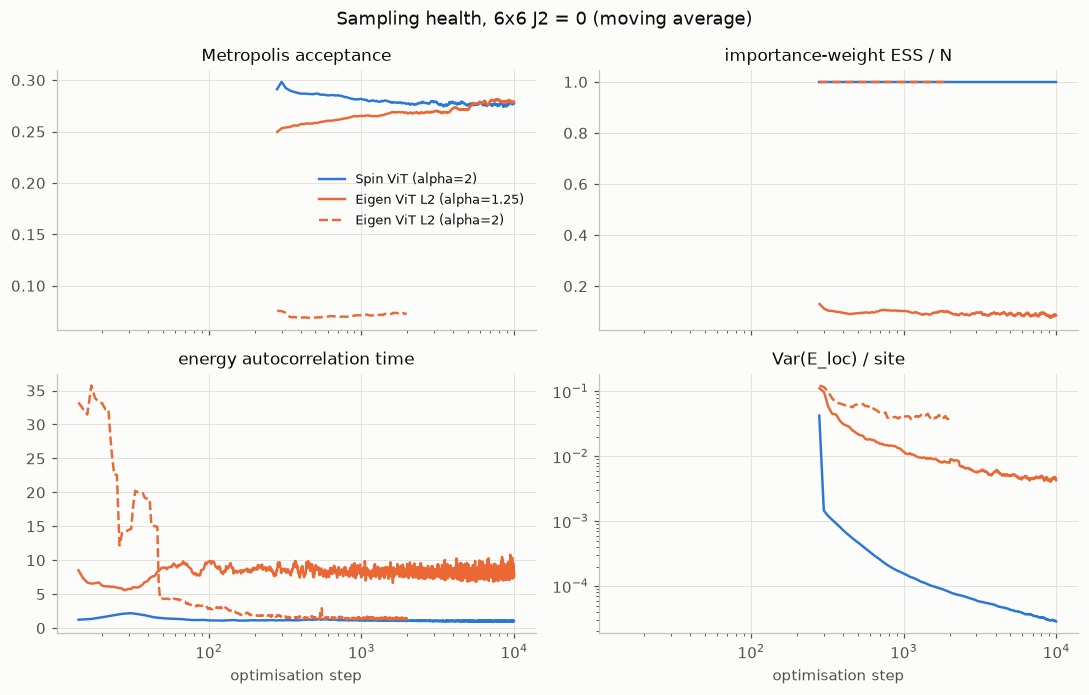

| run (last ~20 diagnostics) | acceptance | ESS_w / N | R-hat log|psi| | tau | Var/site |
|---|---|---|---|---|---|
| Spin ViT (alpha=2) | 0.28 | 1.00 | 1.017 | 1.0 | 2.9e-05 |
| Eigen ViT L2 (alpha=1.25) | 0.28 | 0.09 | 1.015 | 8.5 | 4.4e-03 |
| Eigen ViT L2 (alpha=2) | 0.07 | 1.00 | 1.054 | 1.4 | 4.3e-02 |
| Eigen ViT L8 best (alpha=1.25 auto) | 0.30 | 0.09 | 1.015 | 8.0 | 1.5e-03 |

In [5]:
S_RUNS = [("spin_vit", "Spin ViT (alpha=2)", C_SPIN, "-"),
          ("eig_L2",   "Eigen ViT L2 (alpha=1.25)", C_EIG, "-"),
          ("eig_L2a2", "Eigen ViT L2 (alpha=2)", C_EIG, "--")]
def diag_series(r, key):
    xs = [d["step"] for d in r["diag"] if isinstance(d.get(key), (int, float))]
    ys = [d[key] for d in r["diag"] if isinstance(d.get(key), (int, float))]
    return np.array(xs), np.array(ys)
def smooth(y, w=15):
    return np.convolve(y, np.ones(w) / w, mode="valid") if len(y) > w else y

fig, axs = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
panels = [("acceptance", "Metropolis acceptance", False), ("ess_w_frac", "importance-weight ESS / N", False),
          ("tau", "energy autocorrelation time", False), ("var_eloc_per_site", "Var(E_loc) / site", True)]
for ax, (key, title, logy) in zip(axs.ravel(), panels):
    for k, lab, c, ls in S_RUNS:
        r = R[k]
        if key == "tau":
            x, y = r["it"], r["tau"]
        else:
            x, y = diag_series(r, key)
        if len(y) == 0:
            continue
        ys = smooth(y); xs = x[len(x) - len(ys):]
        ax.plot(xs, ys, color=c, ls=ls, lw=1.6, label=lab)
    ax.set_title(title); ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
for ax in axs[1]:
    ax.set_xlabel("optimisation step")
axs[0, 0].legend(fontsize=8.5)
fig.suptitle("Sampling health, 6x6 J2 = 0 (moving average)", color=INK)
fig.tight_layout(); plt.show()

rows = []
for k, lab, _, _ in S_RUNS + [("eig_best", "Eigen ViT L8 best (alpha=1.25 auto)", None, None)]:
    r = R[k]; tail = r["diag"][-20:]
    mean = lambda key: np.mean([d[key] for d in tail if isinstance(d.get(key), (int, float))]) if tail else float("nan")
    n = len(r["tau"])
    rows.append([lab, f"{mean('acceptance'):.2f}", f"{mean('ess_w_frac'):.2f}", f"{mean('rhat_logpsi'):.3f}",
                 f"{np.nanmean(r['tau'][max(0, n - 300):]):.1f}", f"{mean('var_eloc_per_site'):.1e}"])
table(["run (last ~20 diagnostics)", "acceptance", "ESS_w / N", "R-hat log|psi|", "tau", "Var/site"], rows)

## 4. Stoquasticity: both bases, as run and after a sign gauge

A Hamiltonian is *stoquastic* in a basis if all its off-diagonal elements are ≤ 0. The ground state can then be chosen positive (Perron–Frobenius), so there is **no sign to learn**. Being non-stoquastic *as written* does not by itself make the sign hard, though. If a simple **sign gauge** (flipping the sign of chosen basis states) makes the Hamiltonian stoquastic, the ground state's sign is exactly that gauge.

**Neither network was given a stoquastic Hamiltonian.** Every run compared in this notebook used `sign_rule = "FF"`, i.e. no Marshall rotation, for the spin-basis and eigenbasis ViT alike. In the spin basis, every exchange element of that Hamiltonian is +½, so *as run* it is completely non-stoquastic. The Marshall gauge (−1)^(N↑ on sublattice A) makes it stoquastic at J2 = 0, and the spin ViT learns that sign on its own (5×10⁻⁶ in §2).

So for both bases we report:

* **as run**: the share of off-diagonal weight Σ|H_ij| that is positive in the Hamiltonian the network actually saw;
* **best simple gauge**: the Marshall gauge for the spin basis. For the eigenbasis, the best of **all 2¹⁶ gauges** s(n) = ±1 on the 16 local eigenstates, applied the same way on every plaquette. The eigenbasis off-diagonal terms are the inter-plaquette bond operators; the intra-plaquette term is diagonal in this basis.

In [6]:
import sys; sys.path.insert(0, str(REPO / "diagnostics"))
import sign_diagnostics_4x4 as sd          # diagnostics/sign_diagnostics_4x4.py
import itertools, scipy.sparse.linalg as sla
basis_fns = sd._load_basis_functions()      # get_ops_2x2 / get_piecewise_Hamiltonian_2D from run_2D_eigenbasis.py
SIGNS16 = np.array(list(itertools.product((1, -1), repeat=16)), float)

def eigen_bonds(J2, sign_rule):
    ops = basis_fns["get_ops_2x2"](sign_rule, 1.0, J2, verbose=False)
    _, bonds = basis_fns["get_piecewise_Hamiltonian_2D"](ops, 1.0, J2, sign_rule)
    return [B - np.diag(np.diag(B)) for B in bonds if np.abs(B - np.diag(np.diag(B))).max() > 1e-12]

def eigen_positive_fraction_as_run(offs):
    """Eigenbasis, no gauge: positive off-diagonal weight / total."""
    return sum(o[o > 0].sum() for o in offs) / sum(np.abs(o).sum() for o in offs)

def best_gauge_positive_fraction(offs):
    """min over the 2^16 per-state gauges of (positive off-diagonal weight)/(total)."""
    total = sum(np.abs(o).sum() for o in offs); bad = np.zeros(len(SIGNS16))
    for off in offs:
        idx = np.argwhere(np.abs(off) > 1e-12)
        a, b = divmod(idx[:, 0], 16); a2, b2 = divmod(idx[:, 1], 16); val = off[idx[:, 0], idx[:, 1]]
        sg = SIGNS16[:, a] * SIGNS16[:, b] * SIGNS16[:, a2] * SIGNS16[:, b2]
        bad += ((sg * val[None, :]) > 0) @ np.abs(val)
    g = int(bad.argmin())
    return bad[g] / total, SIGNS16[g]

def marshall_sign(up):
    """(-1)^{N_up on sublattice A} for every 4x4 basis state."""
    coords = {sd.site(X, Y): (X, Y) for X in range(4) for Y in range(4)}
    A = [s for s, (X, Y) in coords.items() if (X + Y) % 2 == 0]
    return np.where(up[A].sum(axis=0) % 2 == 0, 1.0, -1.0)

def spin_positive_fraction(J2, marshall):
    """Spin basis, 4x4. sd.build_hamiltonian is exactly the convention of the
    spin-ViT runs (sign_rule FF: exchange +1/2). marshall=True applies the gauge."""
    H, up = sd.build_hamiltonian(J2)
    m = marshall_sign(up) if marshall else np.ones(H.shape[0])
    Hc = H.tocoo(); off = Hc.row != Hc.col
    v = Hc.data[off] * m[Hc.row[off]] * m[Hc.col[off]]
    return np.abs(v[v > 0]).sum() / np.abs(v).sum()

stoq = {}
for J2 in (0.0, 0.5):
    offs_ff = eigen_bonds(J2, (False, False))
    stoq[(J2, "spin_raw")] = spin_positive_fraction(J2, marshall=False)
    stoq[(J2, "spin")] = spin_positive_fraction(J2, marshall=True)
    stoq[(J2, "eig_raw")] = eigen_positive_fraction_as_run(offs_ff)
    stoq[(J2, "FF")] = best_gauge_positive_fraction(offs_ff)
    stoq[(J2, "TF")] = best_gauge_positive_fraction(eigen_bonds(J2, (True, False)))
table(["J2", "spin basis, **as run** (FF)", "spin basis + Marshall gauge",
       "eigenbasis, **as run** (FF)", "eigenbasis, best of 2^16 gauges (FF)", "eigenbasis, best gauge (TF frame)"],
      [[J2, f"{stoq[(J2, 'spin_raw')]:.1%}", f"{stoq[(J2, 'spin')]:.1%}", f"{stoq[(J2, 'eig_raw')]:.1%}",
        f"{stoq[(J2, 'FF')][0]:.1%}", f"{stoq[(J2, 'TF')][0]:.1%}"] for J2 in (0.0, 0.5)])
display(Markdown(
    "*Share of off-diagonal weight that is **positive** (0% = stoquastic, ~50% = random signs). "
    "Read across each row:*\n\n"
    "* *Spin basis: 100% as run, but one simple gauge removes all of it at J2 = 0. At J2 = 0.5 "
    "the remainder is exactly the frustrating J2 bonds, J2/(J1+J2) = 1/3.*\n"
    "* *Eigenbasis: ~51% as run. The best of 65,536 gauges barely moves it, to ~46%, close to "
    "random.*\n"
    "* *The FF/TF frame does not matter: the global Marshall rotation factorises into plaquette-"
    "local rotations, so the two plaquette eigenbases give the same matrices up to relabelling.*"))

| J2 | spin basis, **as run** (FF) | spin basis + Marshall gauge | eigenbasis, **as run** (FF) | eigenbasis, best of 2^16 gauges (FF) | eigenbasis, best gauge (TF frame) |
|---|---|---|---|---|---|
| 0.0 | 100.0% | 0.0% | 51.4% | 46.0% | 46.0% |
| 0.5 | 100.0% | 33.3% | 51.7% | 46.7% | 46.7% |

*Share of off-diagonal weight that is **positive** (0% = stoquastic, ~50% = random signs). Read across each row:*

* *Spin basis: 100% as run, but one simple gauge removes all of it at J2 = 0. At J2 = 0.5 the remainder is exactly the frustrating J2 bonds, J2/(J1+J2) = 1/3.*
* *Eigenbasis: ~51% as run. The best of 65,536 gauges barely moves it, to ~46%, close to random.*
* *The FF/TF frame does not matter: the global Marshall rotation factorises into plaquette-local rotations, so the two plaquette eigenbases give the same matrices up to relabelling.*

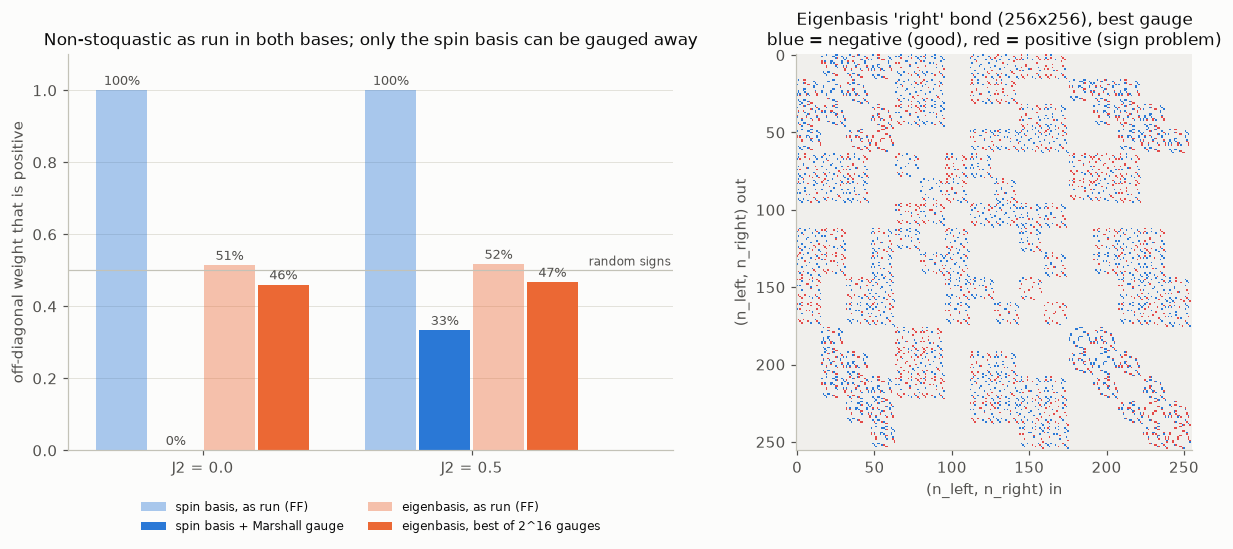

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.0), gridspec_kw={"width_ratios": [1.25, 1]})
# (a) positive share: as run vs best simple gauge, both bases
J2s = [0.0, 0.5]; w = 0.19; xs = np.arange(len(J2s)); gap = 0.01
bars = [("spin_raw", "spin basis, as run (FF)", C_SPIN, 0.4),
        ("spin",     "spin basis + Marshall gauge", C_SPIN, 1.0),
        ("eig_raw",  "eigenbasis, as run (FF)", C_EIG, 0.4),
        ("FF",       "eigenbasis, best of 2^16 gauges", C_EIG, 1.0)]
for i, (key, lab, c, al) in enumerate(bars):
    vals = [stoq[(j, key)][0] if key == "FF" else stoq[(j, key)] for j in J2s]
    pos = xs + (i - 1.5) * (w + gap)
    a1.bar(pos, vals, w, color=c, alpha=al, label=lab)
    for x, v in zip(pos, vals):
        a1.text(x, v + 0.015, f"{v:.0%}", ha="center", color=INK2, fontsize=8.5)
a1.axhline(0.5, color=AXIS, lw=0.8)
a1.text(1.74, 0.505, "random signs", color=INK2, fontsize=8, ha="right", va="bottom")
a1.set_xticks(xs, [f"J2 = {j}" for j in J2s]); a1.set_xlim(-0.5, 1.75); a1.set_ylim(0, 1.1)
a1.grid(axis="x", visible=False); a1.set_ylabel("off-diagonal weight that is positive")
a1.set_title("Non-stoquastic as run in both bases; only the spin basis can be gauged away")
a1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
# (b) sign pattern of one inter-plaquette bond after the best gauge
offs = eigen_bonds(0.0, (False, False)); s = stoq[(0.0, "FF")][1]
gauge = np.kron(s, s); B = gauge[:, None] * offs[0] * gauge[None, :]
im = np.sign(np.where(np.abs(B) > 1e-12, B, 0))
a2.imshow(im, cmap=ListedColormap([C_SPIN, "#f0efec", "#e34948"]), vmin=-1, vmax=1, interpolation="nearest")
a2.set_title("Eigenbasis 'right' bond (256x256), best gauge\nblue = negative (good), red = positive (sign problem)")
a2.set_xlabel("(n_left, n_right) in"); a2.set_ylabel("(n_left, n_right) out"); a2.grid(False)
fig.tight_layout(); plt.show()

### Why the spin-basis sign is easy to learn and the eigenbasis sign is not

In the spin basis the gauge that removes the problem is a **product of single-site factors**: ψ(σ) = (−1)^(N↑ on A) |ψ(σ)|, i.e.

  log ψ(σ) = log|ψ(σ)| + iπ Σ_{i∈A} n↑_i,

a phase that is **linear in the spins**. The ViT's patch embedding is itself linear in the spins and its output is complex, so this phase is almost directly representable. The check below confirms the exact ground-state sign is the Marshall sign on every amplitude at J2 = 0, and how far it departs at J2 = 0.5.

In the eigenbasis no factorised rule of this kind exists: even the best of all 2¹⁶ per-state gauges leaves ~46% of the off-diagonal weight positive. The sign is a genuinely many-body function of the configuration, which the network fails to learn (§6).

In [8]:
rows = []
for J2 in (0.0, 0.5):
    H, up = sd.build_hamiltonian(J2)
    w_, V_ = sla.eigsh(H, k=1, which="SA"); psi = V_[:, 0]
    m = marshall_sign(up); nz = np.abs(psi) > 1e-12
    agree = np.sign(psi[nz]) * m[nz]
    g = 1.0 if (psi[nz] ** 2 * (agree > 0)).sum() >= 0.5 else -1.0        # undo the global sign
    match = agree * g > 0
    rows.append([J2, f"{match.mean():.4%}", f"{(psi[nz] ** 2 * ~match).sum():.4f}"])
table(["J2", "nonzero amplitudes whose sign = Marshall sign", "GS weight with the wrong sign under Marshall"], rows)

| J2 | nonzero amplitudes whose sign = Marshall sign | GS weight with the wrong sign under Marshall |
|---|---|---|
| 0.0 | 100.0000% | 0.0000 |
| 0.5 | 58.4771% | 0.0127 |

## 5. Sign structure of the exact ground state (4×4, exact diagonalisation)

Rotating into the plaquette eigenbasis is a *unitary change of local basis*, so the physics is unchanged. What changes is the function the network must represent. Each eigenbasis amplitude is an interfering, signed sum over the spin configurations of every plaquette. Below we measure, on the exact 4×4 ground state:

* **wrong-sign weight**: the share of |ψ|² whose sign the *best* simple rule gets wrong. In the spin basis we search all 2¹⁶ rules (−1)^(Σ_{i∈S} n↑_i), which include Marshall's. In the eigenbasis we search all 2¹⁶ per-state gauges.
* **concentration**: how many configurations hold 99% of the weight.
* **plaquette occupation**: how often a plaquette sits in each of its 16 eigenstates.

In [9]:
J2_GRID = [0.0, 0.2, 0.4, 0.5, 0.55, 0.6]
grid4 = np.stack(np.meshgrid(*[np.arange(16)] * 4, indexing="ij"), -1).reshape(-1, 4)
SIGN = {}
for J2 in J2_GRID:
    H, up = sd.build_hamiltonian(J2)
    w_, V_ = sla.eigsh(H, k=1, which="SA"); psi = V_[:, 0]
    _, _, v = basis_fns["get_ops_2x2"]((False, False), 1.0, J2, verbose=False, return_qn=True, return_basis=True)
    Psi = np.einsum("an,bm,co,dp,abcd->nmop", v, v, v, v, psi.reshape(16, 16, 16, 16), optimize=True)
    c99 = lambda p: int(np.searchsorted(np.cumsum(np.sort(p)[::-1]), 0.99) + 1)
    SIGN[J2] = dict(E0=w_[0] / 16, ws_spin=sd.wrong_sign_weight_spin(psi, up), ws_eig=sd.wrong_sign_weight_eigen(Psi),
                    c99_spin=c99(psi ** 2), c99_eig=c99((Psi ** 2).ravel()),
                    occ=(Psi ** 2).sum(axis=(1, 2, 3)))
table(["J2", "E0/site (exact 4x4)", "wrong-sign weight: spin", "wrong-sign weight: eigen", "configs for 99%: spin", "configs for 99%: eigen"],
      [[J2, f"{d['E0']:+.6f}", f"{max(d['ws_spin'], 0.0):.3f}", f"**{d['ws_eig']:.3f}**", d["c99_spin"], d["c99_eig"]] for J2, d in SIGN.items()])

| J2 | E0/site (exact 4x4) | wrong-sign weight: spin | wrong-sign weight: eigen | configs for 99%: spin | configs for 99%: eigen |
|---|---|---|---|---|---|
| 0.0 | -0.701780 | 0.000 | **0.066** | 9678 | 744 |
| 0.2 | -0.619874 | 0.000 | **0.089** | 8057 | 950 |
| 0.4 | -0.551148 | 0.000 | **0.131** | 5621 | 1303 |
| 0.5 | -0.528620 | 0.013 | **0.158** | 4365 | 1616 |
| 0.55 | -0.523595 | 0.038 | **0.170** | 5228 | 1568 |
| 0.6 | -0.525896 | 0.102 | **0.169** | 6040 | 1672 |

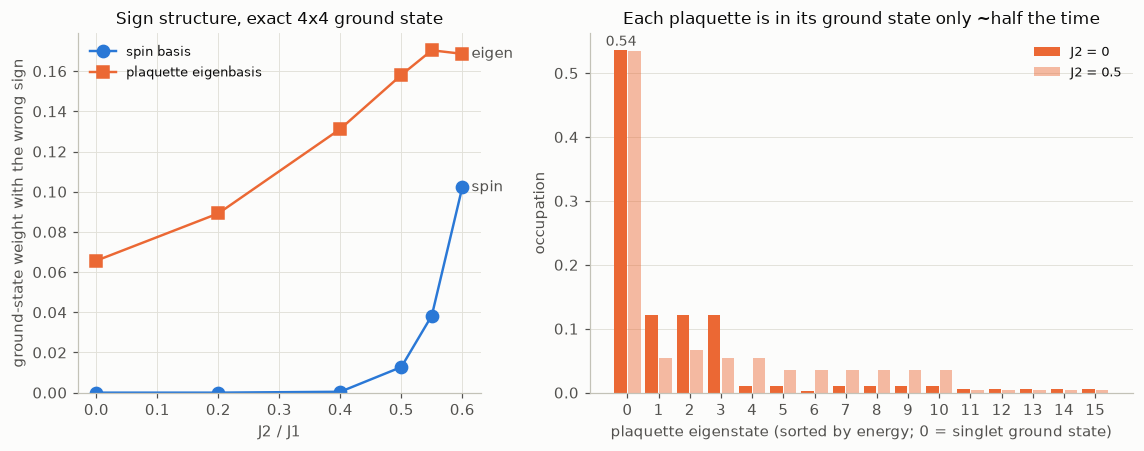

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1, 1.35]})
ws_s = [SIGN[j]["ws_spin"] for j in J2_GRID]; ws_e = [SIGN[j]["ws_eig"] for j in J2_GRID]
a1.plot(J2_GRID, ws_s, "-o", color=C_SPIN, ms=8, label="spin basis")
a1.plot(J2_GRID, ws_e, "-s", color=C_EIG, ms=8, label="plaquette eigenbasis")
a1.annotate("spin", (J2_GRID[-1], ws_s[-1]), xytext=(6, 0), textcoords="offset points", color=INK2, va="center")
a1.annotate("eigen", (J2_GRID[-1], ws_e[-1]), xytext=(6, 0), textcoords="offset points", color=INK2, va="center")
a1.set_xlabel("J2 / J1"); a1.set_ylabel("ground-state weight with the wrong sign")
a1.set_title("Sign structure, exact 4x4 ground state"); a1.set_ylim(bottom=0); a1.legend(fontsize=8.5, loc="upper left")
idx = np.arange(16); w = 0.4
a2.bar(idx - w / 2 - 0.02, SIGN[0.0]["occ"], w, color=C_EIG, label="J2 = 0")
a2.bar(idx + w / 2 + 0.02, SIGN[0.5]["occ"], w, color=C_EIG, alpha=0.45, label="J2 = 0.5")
a2.set_xticks(idx); a2.set_xlabel("plaquette eigenstate (sorted by energy; 0 = singlet ground state)")
a2.set_ylabel("occupation"); a2.set_title("Each plaquette is in its ground state only ~half the time")
a2.annotate(f"{SIGN[0.0]['occ'][0]:.2f}", (0 - w / 2, SIGN[0.0]["occ"][0]), xytext=(0, 3), textcoords="offset points",
            ha="center", color=INK2, fontsize=9)
a2.grid(axis="x", visible=False); a2.legend(fontsize=8.5)
fig.tight_layout(); plt.show()

**Reading the trend.** The eigenbasis carries a sizeable sign structure at every coupling (6.6% → 17%), and its weight is far more concentrated. The spin basis is sign-free up to J2 ≈ 0.4 and then picks up a sign structure of its own as frustration grows (1.3% at J2 = 0.5, 10.2% at 0.6). So the spin basis is ahead at every J2 measured, but its lead narrows deep in the frustrated regime. That is where a better *local* basis would have the most room to help, if one exists.

## 6. Controlled experiment: fit the ViT directly to the exact ground state

This removes VMC entirely: no sampling, no Hamiltonian in the loss. The same ViT is trained to maximise its fidelity with the exact 4×4 ground state, summed over all 12,870 configurations of the Sz = 0 sector (Adam, 2,000 steps, 2 seeds, B200 GPU). Only the target's basis changes:

* **spin**: the ground state in the spin basis
* **eigen**: the same state in the plaquette eigenbasis
* **eigen + exact sign**: the eigenbasis network learns only |Ψ|; the exact signs are supplied (a "sign oracle")
* **variants**: the eigenbasis network with content-dependent attention (`s` = softmax(α + QK), `d` = α + softmax(QK)) and/or a separate amplitude/phase output head

**What "infidelity" means here.** Let t(x) be the exact ground-state amplitudes in the fit's basis (real, normalised) and ψ_θ(x) = exp f_θ(x) the network (complex). Summing over all 12,870 configurations x,

  F = |Σ_x t(x) ψ_θ(x)|² / ( Σ_x |ψ_θ(x)|² · Σ_x t(x)² ),  infidelity = 1 − F,

and the training loss is −log F.
* F is insensitive to the normalisation and global phase of ψ_θ.
* The basis change is unitary, so F is the overlap of the *physical* states, and infidelities are directly comparable between the spin and eigenbasis fits.
* For the sign oracle, ψ_θ(x) = exp(Re f_θ(x)) · sign t(x).
* Reported values are the best (lowest) reached in 2,000 steps; ΔE/E0 is the energy error of that same state.
* These are short supervised fits meant for *comparing bases*. They are not converged, so their numbers are not comparable to the 6×6 VMC errors in §2.

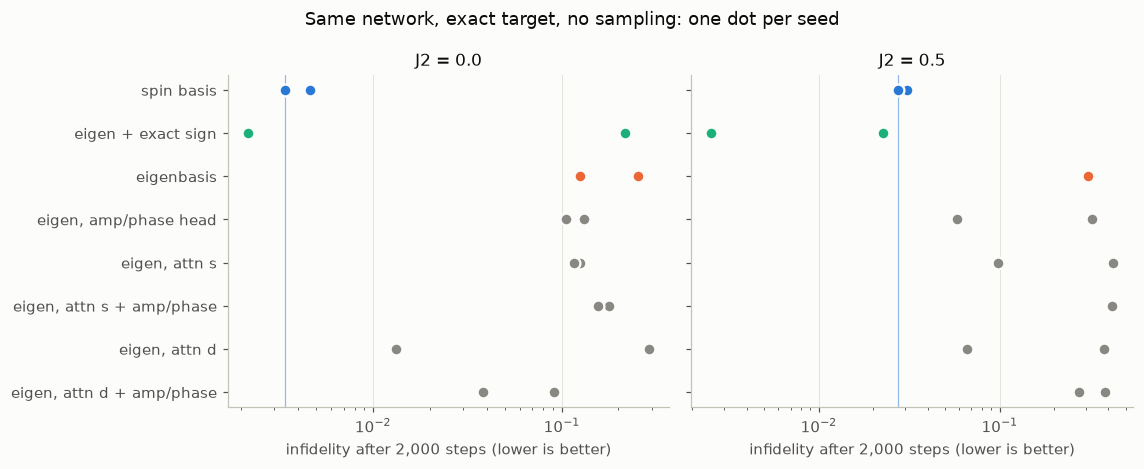

| J2 | fit | params | infidelity (seed 0 / 1) | dE/E0 (seed 0 / 1) |
|---|---|---|---|---|
| 0.0 | spin basis | 116,664 | 3.4e-03 / 4.7e-03 | 2.1e-03 / 3.3e-03 |
| 0.0 | eigen + exact sign | 116,736 | 2.2e-03 / 2.2e-01 | 1.7e-03 / 1.2e-01 |
| 0.0 | eigenbasis | 116,736 | 1.3e-01 / 2.5e-01 | 5.3e-02 / 1.6e-01 |
| 0.0 | eigen, amp/phase head | 116,594 | 1.1e-01 / 1.3e-01 | 4.6e-02 / 5.4e-02 |
| 0.0 | eigen, attn s | 137,760 | 1.2e-01 / 1.2e-01 | 5.0e-02 / 5.6e-02 |
| 0.0 | eigen, attn s + amp/phase | 137,618 | 1.8e-01 / 1.6e-01 | 7.1e-02 / 6.6e-02 |
| 0.0 | eigen, attn d | 137,760 | 1.3e-02 / 2.9e-01 | 8.0e-03 / 1.1e-01 |
| 0.0 | eigen, attn d + amp/phase | 137,618 | 9.1e-02 / 3.8e-02 | 4.2e-02 / 1.9e-02 |
| 0.5 | spin basis | 116,664 | 3.1e-02 / 2.8e-02 | 2.0e-02 / 1.8e-02 |
| 0.5 | eigen + exact sign | 116,736 | 2.6e-03 / 2.3e-02 | 1.9e-03 / 1.6e-02 |
| 0.5 | eigenbasis | 116,736 | 3.0e-01 / 3.1e-01 | 1.4e-01 / 1.1e-01 |
| 0.5 | eigen, amp/phase head | 116,594 | 3.2e-01 / 5.8e-02 | 1.4e-01 / 2.5e-02 |
| 0.5 | eigen, attn s | 137,760 | 9.8e-02 / 4.2e-01 | 4.1e-02 / 1.8e-01 |
| 0.5 | eigen, attn s + amp/phase | 137,618 | 4.2e-01 / 4.2e-01 | 1.5e-01 / 1.2e-01 |
| 0.5 | eigen, attn d | 137,760 | 3.8e-01 / 6.6e-02 | 1.5e-01 / 3.6e-02 |
| 0.5 | eigen, attn d + amp/phase | 137,618 | 3.8e-01 / 2.8e-01 | 1.8e-01 / 1.0e-01 |

In [11]:
fits = [json.loads(l) for l in open(DIAG_DIR / "results.jsonl")]
order = ["spin", "eigen+sign", "eigen", "eigen[factored,amp]", "eigen[s,lc]", "eigen[s,amp]", "eigen[d,lc]", "eigen[d,amp]"]
pretty = {"spin": "spin basis", "eigen+sign": "eigen + exact sign", "eigen": "eigenbasis",
          "eigen[factored,amp]": "eigen, amp/phase head", "eigen[s,lc]": "eigen, attn s",
          "eigen[s,amp]": "eigen, attn s + amp/phase", "eigen[d,lc]": "eigen, attn d",
          "eigen[d,amp]": "eigen, attn d + amp/phase"}
colour = lambda f: C_SPIN if f == "spin" else C_ORACLE if f == "eigen+sign" else C_EIG if f == "eigen" else C_MUTED
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.3), sharey=True)
for ax, J2 in zip(axs, (0.0, 0.5)):
    for row, f in enumerate(order):
        vals = [r["infidelity"] for r in fits if r["J2"] == J2 and r["fit"] == f]
        ax.scatter(vals, [row] * len(vals), s=60, color=colour(f), edgecolor=SURF, linewidth=1.5, zorder=3)
    spin_best = min(r["infidelity"] for r in fits if r["J2"] == J2 and r["fit"] == "spin")
    ax.axvline(spin_best, color=C_SPIN, lw=0.8, alpha=0.5)
    ax.set_xscale("log"); ax.set_title(f"J2 = {J2}"); ax.set_xlabel("infidelity after 2,000 steps (lower is better)")
    ax.grid(axis="y", visible=False)
axs[0].set_yticks(range(len(order)), [pretty[f] for f in order]); axs[0].invert_yaxis()
fig.suptitle("Same network, exact target, no sampling: one dot per seed", color=INK)
fig.tight_layout(); plt.show()

rows = []
for J2 in (0.0, 0.5):
    for f in order:
        rs = [r for r in fits if r["J2"] == J2 and r["fit"] == f]
        inf = [r["infidelity"] for r in rs]
        rows.append([J2, pretty[f], f"{rs[0]['n_params']:,}", " / ".join(f"{x:.1e}" for x in inf),
                     " / ".join(f"{r['rel_energy_error']:.1e}" for r in rs)])
table(["J2", "fit", "params", "infidelity (seed 0 / 1)", "dE/E0 (seed 0 / 1)"], rows)

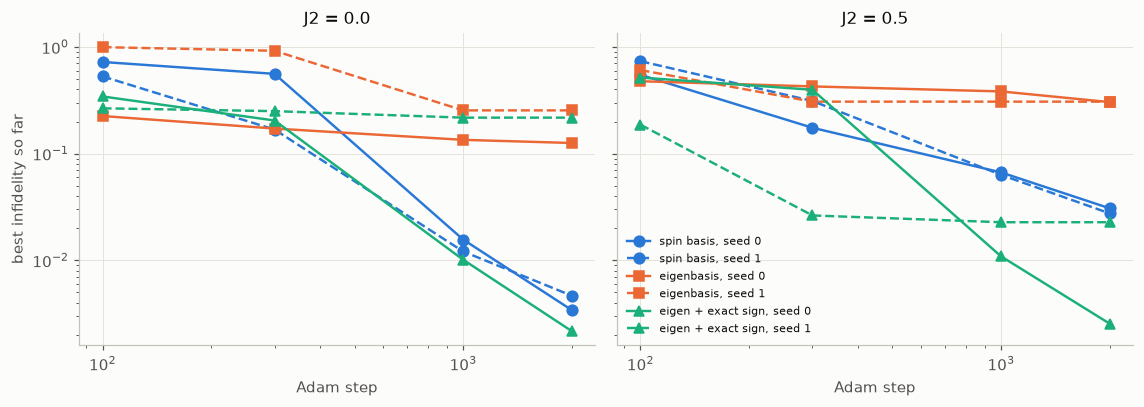

*Curves are best-so-far values at the logged checkpoints, so a flat stretch may be a stall or a later divergence; the oracle's stuck seed (J2 = 0, seed 1) is one such stretch.*

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, J2 in zip(axs, (0.0, 0.5)):
    for f, mk in (("spin", "o"), ("eigen", "s"), ("eigen+sign", "^")):
        for r in [r for r in fits if r["J2"] == J2 and r["fit"] == f]:
            c = r["infidelity_curve"]; steps = sorted(int(k) for k in c)
            ax.plot(steps, [c[str(s)] for s in steps], marker=mk, ms=7, color=colour(f),
                    ls="-" if r["seed"] == 0 else "--", label=f"{pretty[f]}, seed {r['seed']}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"J2 = {J2}"); ax.set_xlabel("Adam step")
axs[0].set_ylabel("best infidelity so far"); axs[1].legend(fontsize=7.5, loc="lower left", ncol=1)
fig.tight_layout(); plt.show()
display(Markdown("*Curves are best-so-far values at the logged checkpoints, so a flat stretch may be a stall "
                 "or a later divergence; the oracle's stuck seed (J2 = 0, seed 1) is one such stretch.*"))

## 7. Conclusions

**Why the plaquette eigenbasis is worse than the spin basis for this ViT:**

1. **It creates a sign problem that the spin basis does not have.** The spin-basis runs were *not* given the Marshall-rotated Hamiltonian (100% positive off-diagonal weight as run). Even so, the ground state's sign is a single factorised rule, Marshall's, a phase linear in the spins, and the ViT learns it by itself. Rotating each plaquette into its eigenbasis mixes many signed spin configurations into every local state. The inter-plaquette couplings then carry signs that no per-state gauge removes (46% positive weight; random is 50%), and the ground state acquires a sign structure (6.6% wrong-sign weight on 4×4).
2. **That sign structure is the specific thing the network fails to learn.** The supervised fits isolate it: the network learns eigenbasis *amplitudes* as well as spin amplitudes once the signs are supplied, and fails without them. No attention or output-head variant closes the gap, so this is not an architecture problem.
3. **The intended advantages do not appear at this cluster size.**
   * There is no shorter sequence: the spin ViT's 2×2 patches are the same 9 tokens.
   * The ground state is not close to a plaquette product state: each plaquette is in its local ground state only ~54% of the time.
   * The concentration of |ψ|² that motivated the basis makes Metropolis sampling *harder* (acceptance 0.07 at α = 2).
4. **It is not a sampling or budget problem.** Changing α or sweep size moves the eigenbasis energy by < 2×. Quadrupling the parameters (L8, 433k) and running 26k steps reaches 7.6×10⁻⁴, still ~150× worse than the 117k-parameter spin ViT.

**Caveats:**
* The stoquasticity, sign and fit evidence is from 4×4 (4 plaquettes), with a gauge search that applies the same rule on every plaquette.
* The fits used 2 seeds, and one oracle seed stalled.
* The 6×6 comparison is at J2 = 0 only, the case most favourable to the spin basis.

**What could still make a cluster basis worthwhile:**
* **Truncation.** Keeping fewer than 16 local states, or using larger clusters, shrinks the problem, which no spin-basis ViT can do. It is a cost argument and is untested here.
* **The frustrated regime.** The spin ViT has not yet been run at 6×6 J2 ≈ 0.5, where its own sign structure appears; on 4×4 the spin basis was still better at every J2 measured, but its lead narrows: 1.3% vs 15.8% wrong-sign weight at J2 = 0.5, 10.2% vs 16.9% at J2 = 0.6. Exact 6×6 references are available for this test: J2 = 0.4 → −0.529745, 0.45 → −0.515657, 0.5 → −0.50381 per site.
* **Lattices with natural clusters.** On Shastry–Sutherland dimers, for example, the cluster is the physical unit cell (as in Viteritti et al. 2025).